# Trabalho 4 — PAM média por intervalo e outliers

Referência (one-shot): [notebook de análise por registro](analisar_pressao_invasiva.ipynb), organizado conforme o [notebook de áudio](../analise_audio/treinar_svm_audio.ipynb).

**Fluxo:** gerar dicionários dos dados brutos; unificar os Parquets; calcular a média da PAM em intervalos por caso; visualizar outliers das médias com Matplotlib.

## Preparação
Execute as células em ordem com pandas, numpy, pyarrow, matplotlib e kernel Jupyter. Configure `INTERVALO_SEGUNDOS` na próxima célula; o padrão é **5 segundos**. São blocos consecutivos sem sobreposição: [0, 5), [5, 10), etc. Não se trata de selecionar apenas uma medição a cada cinco segundos.

A média usa valores finitos da PAM após `abs()` e eventual exclusão opcional de possíveis flushes, conforme a transformação do notebook anterior. Originais e indicadores de valores negativos são preservados. Essa transformação não valida clinicamente o sinal.

As saídas são gravadas em uma pasta própria para cada intervalo. Reexecutar o mesmo intervalo substitui suas saídas. O notebook anterior e os Parquets de origem permanecem intactos. A análise IQR é retrospectiva; não é um detector clínico validado em tempo real.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import platform
import importlib.metadata

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Defina RAIZ_CONFIG antes desta célula para usar outra pasta deteccao_anomalias.
candidatos = [p / r for p in [Path.cwd(), *Path.cwd().parents]
              for r in (Path('.'), Path('deteccao_anomalias'), Path('trabalho4/deteccao_anomalias'))]
RAIZ = Path(RAIZ_CONFIG).resolve() if 'RAIZ_CONFIG' in globals() else next(
    (p.resolve() for p in candidatos if (p / 'vitaldb/vitaldb_200/sinais').is_dir()), None)
if RAIZ is None:
    raise FileNotFoundError('Defina RAIZ_CONFIG para a pasta deteccao_anomalias.')
BASE = RAIZ / 'vitaldb/vitaldb_200'
REFERENCIA = RAIZ / 'vitaldb/vitaldb_50'
# Parâmetro em segundos: altere este valor e execute todas as células.
INTERVALO_SEGUNDOS = globals().get('INTERVALO_SEGUNDOS_CONFIG', 5)
if (isinstance(INTERVALO_SEGUNDOS, (bool, np.bool_))
        or not isinstance(INTERVALO_SEGUNDOS, (int, np.integer))
        or INTERVALO_SEGUNDOS <= 0):
    raise ValueError('INTERVALO_SEGUNDOS deve ser um inteiro positivo em segundos.')
SAIDA = BASE / 'analise_por_intervalo' / f'{INTERVALO_SEGUNDOS}s' 
FIGURAS = SAIDA / 'figuras'
FIGURAS.mkdir(parents=True, exist_ok=True)
ARQUIVOS = sorted((BASE / 'sinais').glob('caso_*.parquet'))
PAM = 'pressao_media_invasiva_mmhg'
# Parâmetros exploratórios de qualidade; não são limiares clínicos validados.
LIMITE_FLUSH_MMHG = 200.0
LIMITE_BAIXO_MMHG = 30.0
JANELA_CONTEXTO_S = 10.0
DURACAO_MAX_FLUSH_S = 10.0
SUBIDA_MIN_FLUSH_MMHG = 50.0
TOLERANCIA_RETORNO_MMHG = 15.0
JANELA_BAIXA_S = 10.0
AMPLITUDE_MAX_BAIXA_MMHG = 2.0
QUEDA_MIN_BAIXA_MMHG = 40.0
MIN_OBSERVACOES_CONTEXTO = 3
EXTENSAO_MIN_CONTEXTO_S = 5.0
LACUNA_MAX_S = 5.0
EXCLUIR_POSSIVEL_FLUSH = False  # Primeiro revisar episódios. Não exclui suspeitas de sinal baixo.

import sys
from dataclasses import asdict
sys.path.insert(0, str(RAIZ))
from qualidade_pam import ParametrosQualidade, avaliar_episodios
PARAMETROS_QUALIDADE = ParametrosQualidade(
    limite_flush=LIMITE_FLUSH_MMHG, limite_baixo=LIMITE_BAIXO_MMHG,
    janela_contexto_s=JANELA_CONTEXTO_S, duracao_max_flush_s=DURACAO_MAX_FLUSH_S,
    subida_min_flush=SUBIDA_MIN_FLUSH_MMHG, tolerancia_retorno=TOLERANCIA_RETORNO_MMHG,
    janela_baixa_s=JANELA_BAIXA_S, amplitude_max_baixa=AMPLITUDE_MAX_BAIXA_MMHG,
    queda_min_baixa=QUEDA_MIN_BAIXA_MMHG, min_observacoes=MIN_OBSERVACOES_CONTEXTO,
    extensao_min_s=EXTENSAO_MIN_CONTEXTO_S, lacuna_max_s=LACUNA_MAX_S,
    excluir_flush=EXCLUIR_POSSIVEL_FLUSH)
FATOR_IQR = 1.5
CASO_GRAFICO = None  # Inteiro para escolher um caso; None escolhe a maior taxa de outliers.
COLUNAS = ['caseid', 'tempo_s', 'frequencia_cardiaca_bpm', 'spo2_percentual',
           PAM, 'pressao_media_nao_invasiva_mmhg']
SCHEMA = pa.schema([('caseid', pa.int64())] + [(c, pa.float64()) for c in COLUNAS[1:]])
if not ARQUIVOS:
    raise FileNotFoundError(f'Nenhum Parquet encontrado em {BASE / "sinais"}')
if not np.isfinite(FATOR_IQR) or FATOR_IQR <= 0:
    raise ValueError('FATOR_IQR deve ser finito e positivo.')
plt.rcParams.update({'figure.figsize': (12, 5), 'axes.grid': True, 'grid.alpha': 0.2})
print(f'{len(ARQUIVOS)} arquivos; {sum(p.stat().st_size for p in ARQUIVOS)/1024**2:.2f} MiB em disco')
print('Saída:', SAIDA)

200 arquivos; 15.63 MiB em disco
Saída: /workspace/trabalho4/deteccao_anomalias/vitaldb/vitaldb_200/analise_por_intervalo/5s


## 1 — Dicionários de dados e inspeção de qualidade

As definições, unidades e tipos semânticos vêm dos dois dicionários de `vitaldb_50`. As contagens, tipos físicos e exemplos são recalculados; não copiamos estatísticas dos 50 casos.

Inspecionamos um arquivo por vez, conferindo esquema, identificação e chave (`caseid`, `tempo_s`). Nulos, infinitos e extremos são contabilizados sem preencher, interpolar ou excluir linhas. Os tipos dos sinais serão padronizados em `float64` na unificação.

`caseid` identifica o caso; `subjectid`, o paciente. Tempos são relativos a cada gravação. Uma linha por segundo não implica uma nova medição por segundo.

In [2]:
def definicoes_markdown(caminho):
    resultado = {}
    for linha in caminho.read_text(encoding='utf-8').splitlines():
        if linha.startswith('| `'):
            campos = [v.strip() for v in linha.strip('|').split('|')]
            resultado[campos[0].strip('`')] = campos[1:]
    return resultado

def tabela_markdown(df):
    # Sem dependência opcional de tabulate; protege separadores em textos clínicos.
    def escapar(v):
        return str(v).replace('|', '&#124;').replace('\n', ' ').replace('\r', ' ')
    linhas = ['| ' + ' | '.join(map(escapar, df.columns)) + ' |',
              '| ' + ' | '.join(['---'] * len(df.columns)) + ' |']
    linhas += ['| ' + ' | '.join(escapar(v) for v in row) + ' |'
               for row in df.itertuples(index=False, name=None)]
    return '\n'.join(linhas)

clinicos = pd.read_csv(BASE / 'clinical_data_200.csv')
selecionados = pd.read_csv(BASE / 'casos_selecionados.csv')
for nome, tabela in [('clínicos', clinicos), ('selecionados', selecionados)]:
    if tabela.empty or tabela['caseid'].isna().any() or tabela['caseid'].duplicated().any():
        raise ValueError(f'Identificadores vazios ou duplicados nos {nome}.')
def_clinicos = definicoes_markdown(REFERENCIA / 'DICIONARIO_DADOS.md')
def_sinais = definicoes_markdown(REFERENCIA / 'DICIONARIO_SINAIS_PARQUET.md')
linhas_clinicas = []
for coluna in clinicos:
    if coluna not in def_clinicos:
        raise ValueError(f'Falta definição clínica para {coluna}.')
    descricao, tipo, unidade = def_clinicos[coluna][:3]
    exemplos = '; '.join(str(v).strip() for v in clinicos[coluna].dropna().unique()[:3]) or '—'
    linhas_clinicas.append([coluna, descricao, tipo, unidade, str(clinicos[coluna].dtype),
                           int(clinicos[coluna].isna().sum()), exemplos])
dicionario_clinico = pd.DataFrame(linhas_clinicas, columns=[
    'Coluna', 'Significado', 'Tipo semântico', 'Unidade / codificação',
    'Tipo pandas', 'Ausentes', 'Exemplos observados'])

estatisticas = {c: {'nulos': 0, 'infinitos': 0, 'todo_nulo': 0, 'min': np.inf,
                    'max': -np.inf, 'pandas': set(), 'arrow': set()} for c in COLUNAS}
inventario = []
casos_vistos = set()
for caminho in ARQUIVOS:
    tabela = pq.read_table(caminho)
    if tabela.column_names != COLUNAS:
        raise ValueError(f'Esquema inesperado: {caminho.name}')
    df = tabela.to_pandas()
    esperado = int(caminho.stem.split('_')[1])
    if df.empty or df['caseid'].isna().any() or not df['caseid'].eq(esperado).all():
        raise ValueError(f'Identificação inválida: {caminho.name}')
    if esperado in casos_vistos:
        raise ValueError(f'Caso repetido: {esperado}')
    casos_vistos.add(esperado)
    if (not np.isfinite(df['tempo_s']).all() or df['tempo_s'].lt(0).any()
            or df.duplicated(['caseid', 'tempo_s']).any()):
        raise ValueError(f'Chave temporal inválida: {caminho.name}')
    tempos = df['tempo_s'].sort_values()
    passos = tempos.diff().dropna()
    inventario.append({'arquivo': caminho.name, 'caseid': esperado, 'linhas': len(df),
                       'inicio_s': tempos.min(), 'fim_s': tempos.max(),
                       'passo_min_s': passos.min(), 'passo_max_s': passos.max()})
    for coluna in COLUNAS:
        s = df[coluna]
        e = estatisticas[coluna]
        e['nulos'] += int(s.isna().sum())
        e['infinitos'] += int(np.isinf(s).sum())
        e['todo_nulo'] += int(s.isna().all())
        finitos = s[np.isfinite(s)]
        if not finitos.empty:
            e['min'] = min(e['min'], float(finitos.min()))
            e['max'] = max(e['max'], float(finitos.max()))
        e['pandas'].add(str(s.dtype))
        e['arrow'].add(str(tabela.schema.field(coluna).type))
if casos_vistos != set(selecionados['caseid']) or casos_vistos != set(clinicos['caseid']):
    raise ValueError('Os conjuntos de casos dos Parquets, seleção e tabela clínica diferem.')
inventario = pd.DataFrame(inventario)
TOTAL = int(inventario['linhas'].sum())
linhas_sinais = []
for coluna, e in estatisticas.items():
    descricao, unidade = def_sinais[coluna][:2]
    linhas_sinais.append([coluna, descricao, unidade, ', '.join(sorted(e['pandas'])),
                          ', '.join(sorted(e['arrow'])), e['nulos'], round(100*e['nulos']/TOTAL, 2),
                          e['infinitos'], e['todo_nulo'],
                          e['min'] if np.isfinite(e['min']) else '—',
                          e['max'] if np.isfinite(e['max']) else '—'])
dicionario_sinais = pd.DataFrame(linhas_sinais, columns=[
    'Coluna', 'Descrição', 'Unidade', 'Tipos pandas', 'Tipos Arrow', 'Ausentes',
    'Ausentes (%)', 'Infinitos', 'Arquivos totalmente nulos', 'Mínimo finito', 'Máximo finito'])
agora = datetime.now(timezone.utc).isoformat()
texto_clinico = f"# Dicionário de dados — clinical_data_200.csv\n\nGerado em {agora}. "
texto_clinico += f"{len(clinicos)} registros, {len(clinicos.columns)} colunas e {clinicos['subjectid'].nunique()} pacientes distintos.\n\n"
texto_clinico += 'Fonte: [CSV local](../clinical_data_200.csv). Definições herdadas do [dicionário de referência](../../vitaldb_50/DICIONARIO_DADOS.md); estatísticas recalculadas nesta execução.\n\n'
texto_clinico += tabela_markdown(dicionario_clinico)
texto_clinico += '\n\n## Convenções e ressalvas\n\nCSV UTF-8, vírgula e ponto decimal. Ausente não significa zero. Tipos pandas são inferidos. caseid identifica casos e subjectid identifica pacientes. Tempos são deslocamentos em segundos, não datas; podem ser negativos. preop_ indica pré-operatório e intraop_ indica totais/doses, não taxas.\n\n'
texto_clinico += 'Conforme a referência: a equivalência de icu_days com los_icu não foi confirmada; o método de preop_sao2 não deve ser inferido pelo nome; preop_pt está em %, preop_bun é nitrogênio ureico e dltubesize contém texto. Exemplos não esgotam os valores permitidos.\n\n'
texto_clinico += 'Não há rótulos de anomalia por instante. Desfechos e totais intraoperatórios podem conter informação futura. Para modelos, separar pacientes por subjectid antes de ajustar parâmetros.\n'
(SAIDA / 'DICIONARIO_DADOS.md').write_text(texto_clinico, encoding='utf-8')
texto_sinais = f'# Dicionário de dados — séries temporais em Parquet\n\nGerado em {agora}. {len(ARQUIVOS)} arquivos e {TOTAL:,} linhas.\n\n'
texto_sinais += 'Fonte: `../sinais/caso_*.parquet`. Definições herdadas do [dicionário de referência](../../vitaldb_50/DICIONARIO_SINAIS_PARQUET.md); estatísticas recalculadas.\n\n'
texto_sinais += tabela_markdown(dicionario_sinais)
texto_sinais += f"\n\nChave (caseid, tempo_s) validada e única. Passos observados entre {inventario['passo_min_s'].min()} e {inventario['passo_max_s'].max()} segundos. Inícios entre {inventario['inicio_s'].min()} e {inventario['inicio_s'].max()} segundos. Todos os casos selecionados possuem Parquet.\n\n"
texto_sinais += 'Cada caso tem origem temporal própria. Uma posição da grade não implica medição nova. A extração usa o último registro processado por célula, sem média, interpolação ou preenchimento. Nulos não distinguem falta de trilha, falta de registro ou valor original ausente. Zeros e extremos foram preservados.\n\n'
texto_sinais += 'Mínimos e máximos finitos são observados, não limites clínicos. Não há indicador de qualidade nem rótulos de anomalia. PAM invasiva e não invasiva permanecem separadas. A unificação padroniza sinais e tempo em float64 e caseid em int64; a tabela acima descreve os arquivos de entrada. Na base unificada, a PAM invasiva recebe abs(); pressao_media_invasiva_original_mmhg preserva o valor bruto em float64 (mmHg) e pam_original_negativa é booleano, verdadeiro para valores finitos originalmente negativos. Isso não valida clinicamente as medições.\n'
texto_sinais += '\n\nA etapa de qualidade usa a PAM original com sinal. pam_tratada.parquet adiciona pam_antes_filtro_mmhg (PAM absoluta antes de qualquer exclusão), episodio_id (inteiro anulável), qualidade_pam (classificação exploratória), instante_decisao_qualidade_s (tempo de disponibilidade da avaliação) e excluido_artefato (booleano). Sem exclusão automática por padrão; a opção de exclusão aplica-se apenas a possíveis flushes. Ausência de contexto preserva o extremo como inconclusivo. A tabela episodios_qualidade_pam contém medidas e justificativas; as definições completas estão no notebook.\n'
(SAIDA / 'DICIONARIO_SINAIS_PARQUET.md').write_text(texto_sinais, encoding='utf-8')
inventario.to_csv(SAIDA / 'inventario.csv', index=False)
display(dicionario_clinico)
display(dicionario_sinais)
print(f'Inspeção concluída: {TOTAL:,} linhas. Dicionários gravados em {SAIDA}')

,Coluna,Significado,Tipo semântico,Unidade / codificação,Tipo pandas,Ausentes,Exemplos observados
0,caseid,Identificador do caso,Identificador,—,int64,0,7; 22; 27
1,subjectid,Identificador anonimizado do paciente,Identificador,—,int64,0,5124; 2813; 5468
2,casestart,Início da gravação,Número,s,int64,0,0
3,caseend,Fim da gravação,Número,s,int64,0,15770; 14374; 17870
4,anestart,Início da anestesia,Número,s,int64,0,477; -719; -2017
...,...,...,...,...,...,...,...
69,intraop_vecu,Vecurônio,Número,mg,int64,0,0
70,intraop_eph,Efedrina,Número,mg,int64,0,0; 5; 20
71,intraop_phe,Fenilefrina,Número,µg,int64,0,0; 170; 30
72,intraop_epi,Epinefrina,Número,µg,int64,0,0; 10; 40


,Coluna,Descrição,Unidade,Tipos pandas,Tipos Arrow,Ausentes,Ausentes (%),Infinitos,Arquivos totalmente nulos,Mínimo finito,Máximo finito
0,caseid,0,0.00,int64,int64,0,0.00,0,0,7.0,6363.0
1,tempo_s,0,0.00,float64,double,0,0.00,0,0,0.0,34876.0
2,frequencia_cardiaca_bpm,336.907,52.80,float32,float,1306407,53.21,0,0,0.0,252.0
3,spo2_percentual,334.473,52.42,float32,float,1283703,52.29,0,0,26.0,100.0
4,pressao_media_invasiva_mmhg,423.809,66.42,"float32, float64","double, float",1330441,54.19,0,19,-96.0,350.0
5,pressao_media_nao_invasiva_mmhg,496.801,77.86,"float32, float64","double, float",2154140,87.74,0,37,31.0,201.0


Inspeção concluída: 2,455,052 linhas. Dicionários gravados em /workspace/trabalho4/deteccao_anomalias/vitaldb/vitaldb_200/analise_por_intervalo/5s


## 2 — Unificar os Parquets e converter a PAM para valor absoluto

Gravamos `sinais_unificados.parquet` incrementalmente, com compressão Snappy, mantendo todas as linhas e ordenando cada caso por tempo.

Aplicamos `abs()` somente à **PAM invasiva**: −20 passa a 20 mmHg; zero continua zero e ausentes continuam ausentes. A coluna `pressao_media_invasiva_original_mmhg` preserva a medição recebida e `pam_original_negativa` identifica valores finitos originalmente negativos. As outras medidas permanecem iguais, inclusive a pressão não invasiva.

**Esta é uma transformação solicitada para exploração, não uma correção clínica validada.** Uma pressão negativa pode indicar problema no sinal; mudar seu sinal não confirma uma medição válida. Os gráficos e o IQR usam a PAM transformada após a anotação de qualidade da próxima etapa (sem exclusão por padrão). Os arquivos de origem e seus dicionários continuam descrevendo os dados brutos.

A escrita usa um arquivo temporário e só substitui a saída após conferir a quantidade de linhas. Os metadados clínicos continuam no CSV, relacionáveis por `caseid`.

In [3]:
PAM_ORIGINAL = 'pressao_media_invasiva_original_mmhg'
FLAG_NEGATIVA = 'pam_original_negativa'
SCHEMA_UNIFICADO = pa.schema(list(SCHEMA) + [
    pa.field(PAM_ORIGINAL, pa.float64()), pa.field(FLAG_NEGATIVA, pa.bool_())])
UNIFICADO = SAIDA / 'sinais_unificados.parquet'
temporario = UNIFICADO.with_suffix('.parquet.part')
try:
    with pq.ParquetWriter(temporario, SCHEMA_UNIFICADO, compression='snappy') as writer:
        for caminho in ARQUIVOS:
            tabela = pq.read_table(caminho).cast(SCHEMA).sort_by([('tempo_s', 'ascending')])
            df = tabela.to_pandas()
            df[PAM_ORIGINAL] = df[PAM].copy()
            df[FLAG_NEGATIVA] = np.isfinite(df[PAM_ORIGINAL]) & df[PAM_ORIGINAL].lt(0)
            df[PAM] = df[PAM_ORIGINAL].abs()
            writer.write_table(pa.Table.from_pandas(df, schema=SCHEMA_UNIFICADO, preserve_index=False))
    if pq.ParquetFile(temporario).metadata.num_rows != TOTAL:
        raise ValueError('A quantidade de linhas mudou durante a unificação.')
    temporario.replace(UNIFICADO)
finally:
    temporario.unlink(missing_ok=True)
dados = pd.read_parquet(UNIFICADO, columns=['caseid', 'tempo_s', PAM, PAM_ORIGINAL, FLAG_NEGATIVA])
assert len(dados) == TOTAL
assert not dados.duplicated(['caseid', 'tempo_s']).any()
print(f'Base unificada: {len(dados):,} linhas; {dados.caseid.nunique()} casos.')
display(dados.head())
# Confere a transformação e a preservação dos ausentes e da proveniência.
np.testing.assert_allclose(dados[PAM], dados[PAM_ORIGINAL].abs(), equal_nan=True)
assert dados[PAM].isna().equals(dados[PAM_ORIGINAL].isna())
assert dados[FLAG_NEGATIVA].equals(np.isfinite(dados[PAM_ORIGINAL]) & dados[PAM_ORIGINAL].lt(0))
assert dados.loc[np.isfinite(dados[PAM]), PAM].ge(0).all()
print(f'{dados[FLAG_NEGATIVA].sum():,} valores finitos negativos convertidos para valor absoluto.')
display(dados.loc[dados[FLAG_NEGATIVA]].head())




Base unificada: 2,455,052 linhas; 200 casos.


,caseid,tempo_s,pressao_media_invasiva_mmhg,pressao_media_invasiva_original_mmhg,pam_original_negativa
0,7,0.0,NaN,NaN,False
1,7,1.0,NaN,NaN,False
2,7,2.0,0.0,0.0,False
3,7,3.0,NaN,NaN,False
4,7,4.0,2.0,2.0,False


37,315 valores finitos negativos convertidos para valor absoluto.


,caseid,tempo_s,pressao_media_invasiva_mmhg,pressao_media_invasiva_original_mmhg,pam_original_negativa
68,7,68.0,2.0,-2.0,True
70,7,70.0,2.0,-2.0,True
72,7,72.0,2.0,-2.0,True
74,7,74.0,2.0,-2.0,True
76,7,76.0,2.0,-2.0,True


## Qualidade da PAM — episódios suspeitos e contexto temporal

A implementação compartilhada está em [qualidade_pam.py](qualidade_pam.py), que deve acompanhar este notebook. Esta etapa substitui a exclusão por ausência de vizinhos exatos em ±5 segundos.

**A heurística usa a coluna de PAM original, com sinal, independentemente de `abs()`.** A base unificada guarda ambas as versões. Depois da anotação, as análises exploratórias continuam usando a PAM absoluta para manter a comparação com os notebooks anteriores. Uma PAM negativa não passa a ser clinicamente válida por essa conversão. Nunca sobrescrevemos os Parquets de origem.

### Parâmetros iniciais

Todos podem ser alterados na primeira célula de código. São escolhas de engenharia para experimentar e revisar, **não critérios clínicos validados**.

| Parâmetro | Padrão | Uso |
| --- | ---: | --- |
| `LIMITE_FLUSH_MMHG` | 200 mmHg | Candidato alto: PAM original estritamente acima do corte |
| `LIMITE_BAIXO_MMHG` | 30 mmHg | Candidato baixo: PAM original estritamente abaixo do corte |
| `JANELA_CONTEXTO_S` | 10 s | Contexto anterior e posterior do episódio |
| `DURACAO_MAX_FLUSH_S` | 10 s | Máximo da extensão temporal observada para possível flush |
| `SUBIDA_MIN_FLUSH_MMHG` | 50 mmHg | Pico menos mediana anterior |
| `TOLERANCIA_RETORNO_MMHG` | 15 mmHg | Diferença absoluta máxima entre medianas posterior e anterior |
| `JANELA_BAIXA_S` | 10 s | Janela móvel recente para sinal baixo |
| `AMPLITUDE_MAX_BAIXA_MMHG` | 2 mmHg | Máximo menos mínimo no trecho recente |
| `QUEDA_MIN_BAIXA_MMHG` | 40 mmHg | Mediana anterior menos mediana recente |
| `MIN_OBSERVACOES_CONTEXTO` | 3 | Mínimo de observações finitas por janela |
| `EXTENSAO_MIN_CONTEXTO_S` | 5 s | Distância mínima entre primeira e última observação da janela |
| `LACUNA_MAX_S` | 5 s | Maior distância permitida entre observações finitas e até a borda do episódio |
| `EXCLUIR_POSSIVEL_FLUSH` | False | Apenas sinalizar por padrão; True exclui somente possíveis flushes da coluna analítica |

### 1. Formar episódios por caso

Ordenamos as leituras pelo tempo e usamos somente valores originais finitos para identificar extremos. Leituras consecutivas do mesmo tipo (alto ou baixo) formam um episódio se o intervalo entre elas não ultrapassar `LACUNA_MAX_S`. Uma leitura finita fora desse tipo ou uma lacuna maior encerra o trecho. Não interpolamos nem misturamos casos.

A duração observada é `último tempo extremo − primeiro tempo extremo`; um ponto isolado tem duração observada zero. Isso não prova a duração contínua do evento. Lacunas curtas podem existir entre as observações; elas não são tratadas como novas medições.

O contexto anterior ocupa `[início − janela, início)` e o posterior `(fim, fim + janela]`. Não exigimos medições exatamente em ±5s. Cada janela precisa ter ao menos três valores finitos distribuídos por cinco segundos, sem lacunas maiores que cinco segundos; a observação mais próxima também deve estar a até cinco segundos da borda do episódio. Ausentes e infinitos não contam.

### 2. Possível flush

Se o episódio alto for breve e houver contexto suficiente:

```text
pico > 200
E duração observada ≤ 10s
E pico − mediana_anterior ≥ 50
E abs(mediana_posterior − mediana_anterior) ≤ 15
→ possivel_flush
```

Exemplo ilustrativo: mediana anterior 82, pico 260 por 3s e mediana posterior 85 mmHg. A subida é 178 mmHg e a diferença após retorno é 3 mmHg. Um episódio alto com duração maior que o máximo é `extremo_preservado`. Um episódio breve sem contexto suficiente é `inconclusivo`; com contexto, mas sem satisfazer subida/retorno, é `extremo_preservado`.

Para confirmar o resultado retrospectivo, exigimos que a gravação alcance o fim da janela posterior. `instante_decisao_s` registra esse momento; a suspeita não estaria disponível no início do episódio. Se a gravação terminar antes, o episódio breve fica inconclusivo.

### 3. Suspeita de sinal baixo quase constante

Durante cada episódio baixo, avaliamos a janela móvel `[t − 10s, t]`, restrita ao episódio e usando somente leituras já recebidas. A referência é a mediana do contexto anterior ao início do episódio, que permanece fixa.

```text
mediana_recente < 30
E max(recente) − min(recente) ≤ 2
E mediana_anterior − mediana_recente ≥ 40
E contexto anterior e recente suficientes
→ suspeita_sinal_baixo_constante
```

A primeira janela que satisfaz a regra define `instante_decisao_s`. O padrão pode levantar hipótese de desconexão/ociosidade, mas **não confirma equipamento desconectado**. Valores baixos reais, atualização lenta e repetições do monitor podem produzir comportamento semelhante. Essa classificação nunca causa exclusão automática, mesmo com `EXCLUIR_POSSIVEL_FLUSH=True`.

### 4. Decisão, preservação e uso em tempo real

| Classificação | Interpretação | Exclusão padrão |
| --- | --- | --- |
| `possivel_flush` | Pico breve com subida e retorno compatíveis | Não; opcional após revisão |
| `suspeita_sinal_baixo_constante` | Queda e baixa variabilidade; investigar qualidade e condição clínica | Não |
| `inconclusivo` | Contexto insuficiente para a regra | Não |
| `extremo_preservado` | Extremo sem evidências suficientes do padrão suspeito | Não |
| `sem_indicio` | Registro fora dos gatilhos; não é atestado de normalidade clínica | Não |
| `sem_medicao` | PAM original ausente/infinita | Não participa das estatísticas finitas |

A tabela de registros recebe uma anotação retrospectiva por episódio. **Não use essa anotação para emitir alertas antes de `instante_decisao_qualidade_s`**. O sinal baixo usa apenas o passado para sua primeira decisão; um flush exige contexto posterior. Uma média em tempo real não deve aguardar silenciosamente a revisão de qualidade para mostrar uma pressão baixa.

Se a exclusão opcional for habilitada, somente os pontos altos do possível flush recebem NaN na PAM analítica. Contextos, valores originais, tempos e outros registros permanecem intactos; não há filtragem em cascata. O motivo e os parâmetros ficam registrados. O simulador Python não é alterado por esta etapa.

### Saídas e revisão

- `episodios_qualidade_pam.csv` e `.parquet`: classe, início/fim, duração observada, pico, medianas, subida, retorno, amplitude/queda, suficiência de contexto e instante de decisão.
- `pam_tratada.parquet`: todos os registros, com `episodio_id`, `qualidade_pam`, `instante_decisao_qualidade_s`, `pam_antes_filtro_mmhg` e `excluido_artefato`.
- `registros_excluidos_artefatos.parquet`: somente exclusões opcionais; vazio por padrão.
- `resumo_qualidade_pam.csv`: episódios e medições por classificação.
- Figuras de episódios: PAM original, PAM analítica e contexto para revisar a decisão; exemplos são selecionados, não representativos nem validação de acurácia.

Esta base não contém rótulos de artefato. Antes de adotar exclusões em produção, revisar os episódios e, quando possível, consultar a onda arterial e anotações nos arquivos `.vital`.

### Referências de contexto (não validam os números propostos)

- [Artifacts annotations in anesthesia blood pressure data by man and machine](https://pmc.ncbi.nlm.nih.gov/articles/PMC7943498/): avaliação de artefatos com anotação e observação da onda arterial.
- [How to measure blood pressure using an arterial catheter](https://pmc.ncbi.nlm.nih.gov/articles/PMC7183114/): avaliação da qualidade da medição e da onda arterial.


In [4]:
# A implementação consulta PAM_ORIGINAL, nunca a PAM convertida para identificar episódios.
dados, episodios = avaliar_episodios(dados, PARAMETROS_QUALIDADE)
assert len(dados) == TOTAL
assert not dados.duplicated(['caseid', 'tempo_s']).any()
assert dados.loc[dados.excluido_artefato, PAM].isna().all()
assert dados.loc[dados.excluido_artefato, 'qualidade_pam'].eq('possivel_flush').all()
np.testing.assert_allclose(dados.loc[~dados.excluido_artefato, PAM],
                           dados.loc[~dados.excluido_artefato, 'pam_antes_filtro_mmhg'], equal_nan=True)
if not EXCLUIR_POSSIVEL_FLUSH:
    assert not dados.excluido_artefato.any()
resumo_qualidade = pd.DataFrame({
    'episodios': episodios.classificacao.value_counts(),
    'registros': dados.qualidade_pam.value_counts(),
}).fillna(0).astype('int64').rename_axis('classificacao')
resumo_filtro = {
    'episodios_por_classe': {str(k): int(v) for k, v in episodios.classificacao.value_counts().items()},
    'registros_por_classe': {str(k): int(v) for k, v in dados.qualidade_pam.value_counts().items()},
    'total_excluido': int(dados.excluido_artefato.sum()),
    'exclusao_flush_habilitada': EXCLUIR_POSSIVEL_FLUSH,
}
dados.to_parquet(SAIDA / 'pam_tratada.parquet', index=False)
dados.loc[dados.excluido_artefato].to_parquet(SAIDA / 'registros_excluidos_artefatos.parquet', index=False)
episodios.to_csv(SAIDA / 'episodios_qualidade_pam.csv', index=False)
episodios.to_parquet(SAIDA / 'episodios_qualidade_pam.parquet', index=False)
resumo_qualidade.to_csv(SAIDA / 'resumo_qualidade_pam.csv')
display(resumo_qualidade)
display(episodios.head(10))
print(f'{len(episodios):,} episódios avaliados; {dados.excluido_artefato.sum():,} registros excluídos.')

registros = dados.copy()


,episodios,registros
classificacao,,
extremo_preservado,1059,15851
inconclusivo,409,47447
possivel_flush,165,592
sem_indicio,0,1052352
sem_medicao,0,1330441
suspeita_sinal_baixo_constante,133,8369


,episodio_id,caseid,tipo,inicio_s,fim_s,duracao_observada_s,n_observacoes,minimo_mmhg,pico_mmhg,subida_mmhg,...,depois_n,depois_extensao_s,depois_lacuna_max_s,depois_distancia_borda_s,depois_suficiente,depois_mediana,depois_amplitude,mediana_baixa_mmhg,amplitude_baixa_mmhg,queda_mmhg
0,1,7,baixo,2.0,751.0,749.0,375,-3.0,26.0,NaN,...,5,8.0,2.0,2.0,True,37.0,7.0,NaN,NaN,NaN
1,2,7,baixo,785.0,1419.0,634.0,318,8.0,29.0,-13.0,...,5,8.0,2.0,2.0,True,99.0,48.0,9.5,13.0,32.5
2,3,7,alto,1667.0,1671.0,4.0,3,214.0,245.0,131.0,...,5,8.0,2.0,2.0,True,181.0,20.0,NaN,NaN,NaN
3,4,7,alto,2973.0,2975.0,2.0,2,254.0,254.0,202.0,...,5,8.0,2.0,2.0,True,75.0,6.0,NaN,NaN,NaN
4,5,7,alto,3964.0,3970.0,6.0,4,212.0,233.0,89.0,...,5,8.0,2.0,2.0,True,114.0,57.0,NaN,NaN,NaN
5,6,7,alto,3986.0,3986.0,0.0,1,227.0,227.0,113.0,...,5,8.0,2.0,2.0,True,168.0,81.0,NaN,NaN,NaN
6,7,7,alto,10723.0,10733.0,10.0,6,218.0,256.0,70.0,...,5,8.0,2.0,2.0,True,107.0,79.0,NaN,NaN,NaN
7,8,7,alto,10749.0,10755.0,6.0,4,224.0,261.0,165.0,...,5,8.0,2.0,2.0,True,111.0,98.0,NaN,NaN,NaN
8,9,7,alto,15139.0,15161.0,22.0,12,214.0,257.0,76.0,...,5,8.0,2.0,2.0,True,139.0,40.0,NaN,NaN,NaN
9,10,7,baixo,15197.0,15221.0,24.0,13,-55.0,-7.0,-120.0,...,0,0.0,NaN,NaN,False,NaN,NaN,-55.0,2.0,168.0


1,766 episódios avaliados; 0 registros excluídos.


### Revisão visual dos episódios

Os exemplos abaixo comparam o sinal original e o analítico. Pontos não conectam lacunas; cores de contexto servem para explicar as regras, não para indicar normalidade clínica.

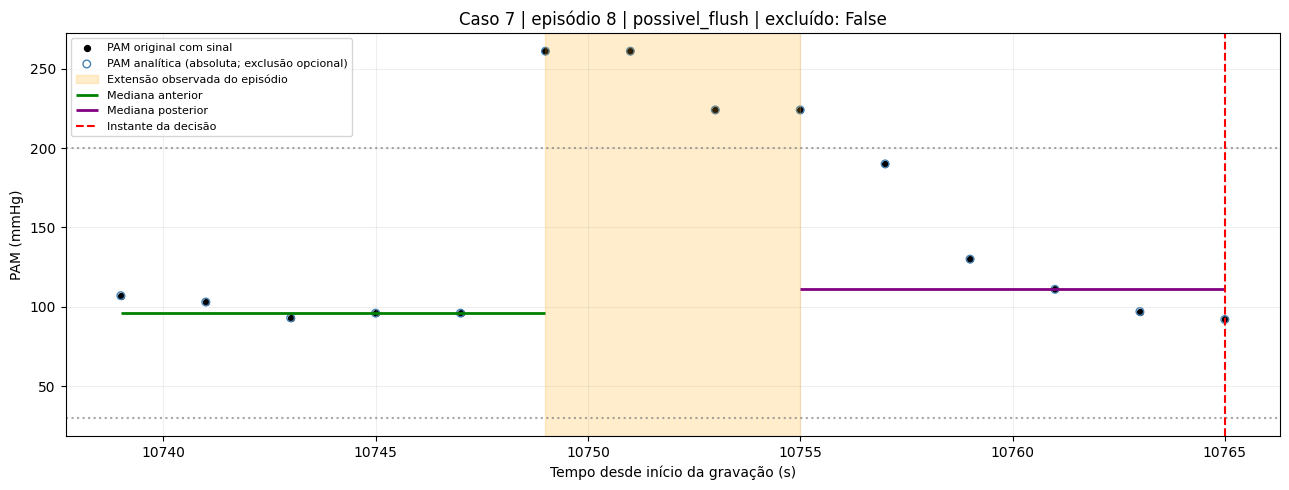

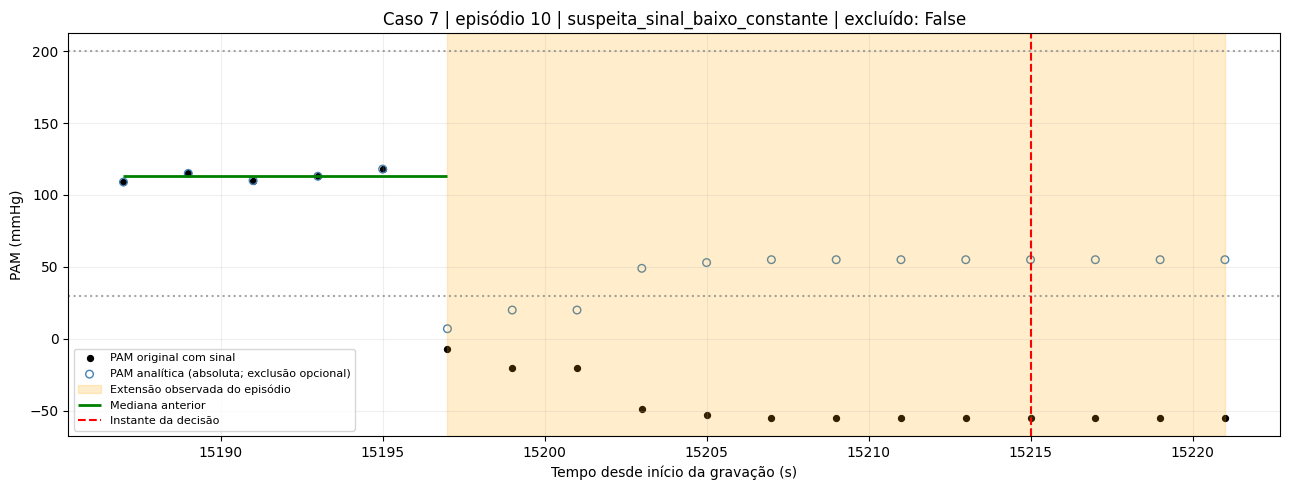

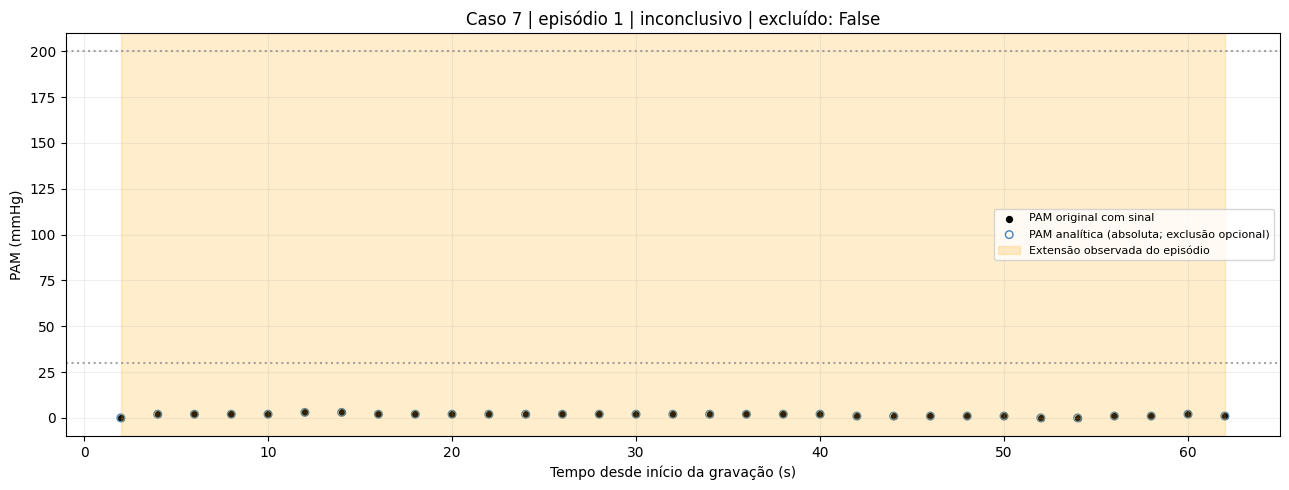

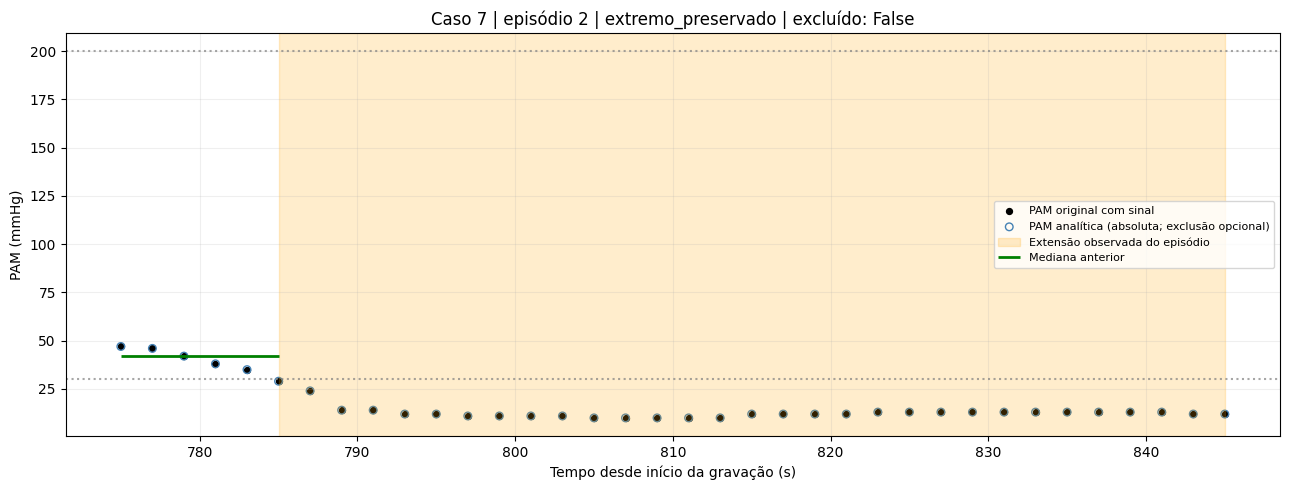

In [5]:
# Um exemplo de cada classificação para inspeção visual (sem selecionar pelo resultado clínico).
classes_revisao = ['possivel_flush', 'suspeita_sinal_baixo_constante', 'inconclusivo', 'extremo_preservado']
for classe in classes_revisao:
    opcoes = episodios.loc[episodios.classificacao.eq(classe)]
    if opcoes.empty:
        print(f'Nenhum episódio classificado como {classe}.')
        continue
    evento = opcoes.iloc[0]
    # Limita a tela inicial de episódios longos; o CSV mantém sua extensão completa.
    inicio_tela = max(0, evento.inicio_s - JANELA_CONTEXTO_S)
    fim_tela = min(evento.fim_s + JANELA_CONTEXTO_S, evento.inicio_s + 60)
    trecho = dados.loc[dados.caseid.eq(evento.caseid) & dados.tempo_s.between(inicio_tela, fim_tela)].sort_values('tempo_s')
    fig, ax = plt.subplots(figsize=(13, 5))
    ax.scatter(trecho.tempo_s, trecho[PAM_ORIGINAL], s=18, color='black', label='PAM original com sinal')
    ax.scatter(trecho.tempo_s, trecho[PAM], s=30, facecolors='none', edgecolors='steelblue', label='PAM analítica (absoluta; exclusão opcional)')
    ax.axvspan(evento.inicio_s, min(evento.fim_s, fim_tela), color='orange', alpha=0.2, label='Extensão observada do episódio')
    for limite in [LIMITE_FLUSH_MMHG, LIMITE_BAIXO_MMHG]:
        ax.axhline(limite, color='gray', linestyle=':', alpha=0.7)
    if np.isfinite(evento.antes_mediana):
        ax.hlines(evento.antes_mediana, inicio_tela, evento.inicio_s, color='green', linewidth=2, label='Mediana anterior')
    if np.isfinite(evento.depois_mediana) and evento.fim_s < fim_tela:
        ax.hlines(evento.depois_mediana, evento.fim_s, fim_tela, color='purple', linewidth=2, label='Mediana posterior')
    if np.isfinite(evento.instante_decisao_s) and evento.instante_decisao_s <= fim_tela:
        ax.axvline(evento.instante_decisao_s, color='red', linestyle='--', label='Instante da decisão')
    ax.set(xlabel='Tempo desde início da gravação (s)', ylabel='PAM (mmHg)',
           title=f'Caso {int(evento.caseid)} | episódio {int(evento.episodio_id)} | {classe} | excluído: {evento.excluido}')
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(FIGURAS / f'qualidade_exemplo_{classe}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)


## 3 — Calcular a média da PAM por intervalo

Cada linha de saída representa um **caso e intervalo**, definido pelo tempo, não pela quantidade de registros. Calculamos `mean(abs(PAM))`, não `abs(mean(PAM))`. A média aritmética ignora ausentes e infinitos, sem interpolação. Intervalos sem observações finitas têm média ausente; zero continua sendo um valor presente.

Mantemos início, fim exclusivo, número de linhas, quantidade de PAMs finitas, percentual de preenchimento entre as linhas existentes e quantidade de valores originalmente negativos. Esse percentual não prova cobertura temporal contínua nem independência das medições. Intervalos sem nenhuma linha entre o início e o fim de um caso também aparecem, vazios. O último bloco pode conter apenas parte do intervalo.

`tempo_s` é o **fim do intervalo**, rótulo temporal do bloco; com o filtro, a média revisada exige também o contexto futuro dos episódios de possível flush. Em tempo real, é necessário aguardar o fechamento do bloco; o último bloco parcial só pode ser finalizado com a indicação de fim do caso. Não há mistura entre casos. Os limites IQR abaixo usam todo o histórico e precisariam ser ajustados previamente em um conjunto de treinamento para uso prospectivo.

In [6]:
def agregar_pam_por_intervalo(registros, intervalo_s):
    if isinstance(intervalo_s, (bool, np.bool_)) or not isinstance(intervalo_s, (int, np.integer)) or intervalo_s <= 0:
        raise ValueError('O intervalo deve ser um inteiro positivo.')
    trabalho = registros.copy()
    if 'excluido_artefato' not in trabalho:
        trabalho['excluido_artefato'] = False
    trabalho['intervalo_id'] = np.floor(trabalho['tempo_s'] / intervalo_s).astype('int64')
    trabalho['pam_finita'] = trabalho[PAM].where(np.isfinite(trabalho[PAM]))
    trabalho['pam_original_finita'] = trabalho[PAM_ORIGINAL].where(np.isfinite(trabalho[PAM_ORIGINAL]))
    agrupado = trabalho.groupby(['caseid', 'intervalo_id'], sort=True).agg(
        **{PAM: ('pam_finita', 'mean'),
           'pam_original_media_mmhg': ('pam_original_finita', 'mean'),
           'n_registros': ('tempo_s', 'size'),
           'n_excluidos_artefatos': ('excluido_artefato', 'sum'),
           'n_pam_validas': ('pam_finita', 'count'),
           'n_pam_originais_negativas': (FLAG_NEGATIVA, 'sum'),
           'primeiro_registro_s': ('tempo_s', 'min'),
           'ultimo_registro_s': ('tempo_s', 'max')})
    # Explicita blocos inteiramente sem linhas, sem preenchê-los com pressão zero.
    chaves = [(caso, bloco) for caso, grupo in trabalho.groupby('caseid')
              for bloco in range(int(grupo.intervalo_id.min()), int(grupo.intervalo_id.max()) + 1)]
    indice = pd.MultiIndex.from_tuples(chaves, names=['caseid', 'intervalo_id'])
    resultado = agrupado.reindex(indice).reset_index()
    contagens = ['n_excluidos_artefatos', 'n_registros', 'n_pam_validas', 'n_pam_originais_negativas']
    resultado[contagens] = resultado[contagens].fillna(0).astype('int64')
    resultado['inicio_intervalo_s'] = resultado.intervalo_id * intervalo_s
    resultado['fim_intervalo_s'] = resultado.inicio_intervalo_s + intervalo_s
    resultado['tempo_s'] = resultado.fim_intervalo_s
    resultado['pam_preenchida_percentual'] = (
        100 * resultado.n_pam_validas / resultado.n_registros.replace(0, np.nan))
    return resultado

dados = agregar_pam_por_intervalo(registros, INTERVALO_SEGUNDOS)
assert dados.n_excluidos_artefatos.sum() == registros.excluido_artefato.sum()
assert dados.n_registros.sum() == len(registros)
assert dados.n_pam_validas.sum() == np.isfinite(registros[PAM]).sum()
assert dados.n_pam_originais_negativas.sum() == registros[FLAG_NEGATIVA].sum()
assert not dados.duplicated(['caseid', 'inicio_intervalo_s']).any()
assert dados.loc[dados.n_pam_validas.eq(0), PAM].isna().all()
dados.to_parquet(SAIDA / 'pam_por_intervalo.parquet', index=False)
print(f'{len(registros):,} registros → {len(dados):,} intervalos de {INTERVALO_SEGUNDOS} segundos.')
print(f'{dados[PAM].notna().sum():,} intervalos com média disponível.')
display(dados.head(10))

# Verificação de fronteiras, isolamento dos casos, ausentes e média dos valores absolutos.
amostra = pd.DataFrame({
    'caseid': [1, 1, 1, 1, 1, 2], 'tempo_s': [0., 4., 5., 6., 10., 0.],
    PAM_ORIGINAL: [-10., 30., 0., np.inf, np.nan, 100.]})
amostra[PAM] = amostra[PAM_ORIGINAL].abs()
amostra[FLAG_NEGATIVA] = np.isfinite(amostra[PAM_ORIGINAL]) & amostra[PAM_ORIGINAL].lt(0)
verificacao = agregar_pam_por_intervalo(amostra, 5)
np.testing.assert_allclose(verificacao[PAM], [20., 0., np.nan, 100.], equal_nan=True)
assert verificacao.n_pam_validas.tolist() == [2, 1, 0, 1]
assert verificacao.tempo_s.tolist() == [5, 10, 15, 5]
# O mesmo código deve respeitar a alteração do parâmetro.
np.testing.assert_allclose(agregar_pam_por_intervalo(amostra, 10)[PAM],
                           [40 / 3, np.nan, 100.], equal_nan=True)
print('Agregação validada: fronteiras, casos separados, ausentes, infinitos e intervalos diferentes.')


2,455,052 registros → 491,093 intervalos de 5 segundos.
450,240 intervalos com média disponível.


,caseid,intervalo_id,pressao_media_invasiva_mmhg,pam_original_media_mmhg,n_registros,n_excluidos_artefatos,n_pam_validas,n_pam_originais_negativas,primeiro_registro_s,ultimo_registro_s,inicio_intervalo_s,fim_intervalo_s,tempo_s,pam_preenchida_percentual
0,7,0,1.000000,1.000000,5,0,2,0,0.0,4.0,0,5,5,40.0
1,7,1,2.000000,2.000000,5,0,2,0,5.0,9.0,5,10,10,40.0
2,7,2,2.666667,2.666667,5,0,3,0,10.0,14.0,10,15,15,60.0
3,7,3,2.000000,2.000000,5,0,2,0,15.0,19.0,15,20,20,40.0
4,7,4,2.000000,2.000000,5,0,3,0,20.0,24.0,20,25,25,60.0
5,7,5,2.000000,2.000000,5,0,2,0,25.0,29.0,25,30,30,40.0
6,7,6,2.000000,2.000000,5,0,3,0,30.0,34.0,30,35,35,60.0
7,7,7,2.000000,2.000000,5,0,2,0,35.0,39.0,35,40,40,40.0
8,7,8,1.333333,1.333333,5,0,3,0,40.0,44.0,40,45,45,60.0
9,7,9,1.000000,1.000000,5,0,2,0,45.0,49.0,45,50,50,40.0


Agregação validada: fronteiras, casos separados, ausentes, infinitos e intervalos diferentes.


## 4 — Outliers das médias e gráficos com Matplotlib

Calculamos Q1 e Q3 sobre as **médias finitas dos intervalos**, não sobre registros individuais. IQR = Q3 − Q1; os limites são Q1 − 1,5 × IQR e Q3 + 1,5 × IQR. Intervalos sem média permanecem sem classificação. IQR zero interrompe a análise.

Cada intervalo com média tem o mesmo peso, independentemente de sua quantidade de valores válidos; os indicadores de preenchimento permitem revisar os blocos pouco preenchidos. Casos mais longos continuam contribuindo com mais intervalos. A agregação suaviza extremos e pode esconder eventos curtos; não estabelece normalidade clínica.

Histograma, boxplot, ranking e série temporal representam médias por intervalo. O caso automático tem a maior proporção de intervalos outliers e não é necessariamente representativo.

Q1=73.00; mediana=82.50; Q3=92.50; IQR=19.50 mmHg
Limites estatísticos: 43.75 e 121.75 mmHg
37,625 outliers em 450,240 intervalos com média (8.36%).
40,853 intervalos sem classificação por falta de média finita.


,intervalos,intervalos_com_media,outliers,outliers_percentual
caseid,,,,
4690,926,872,326,37.385321
2473,888,845,309,36.568047
2178,815,757,274,36.195509
4635,1795,1705,449,26.334311
4786,1113,992,258,26.008065
6094,981,860,217,25.232558
631,3817,3805,935,24.57293
3153,1383,1302,307,23.579109
753,727,672,156,23.214286


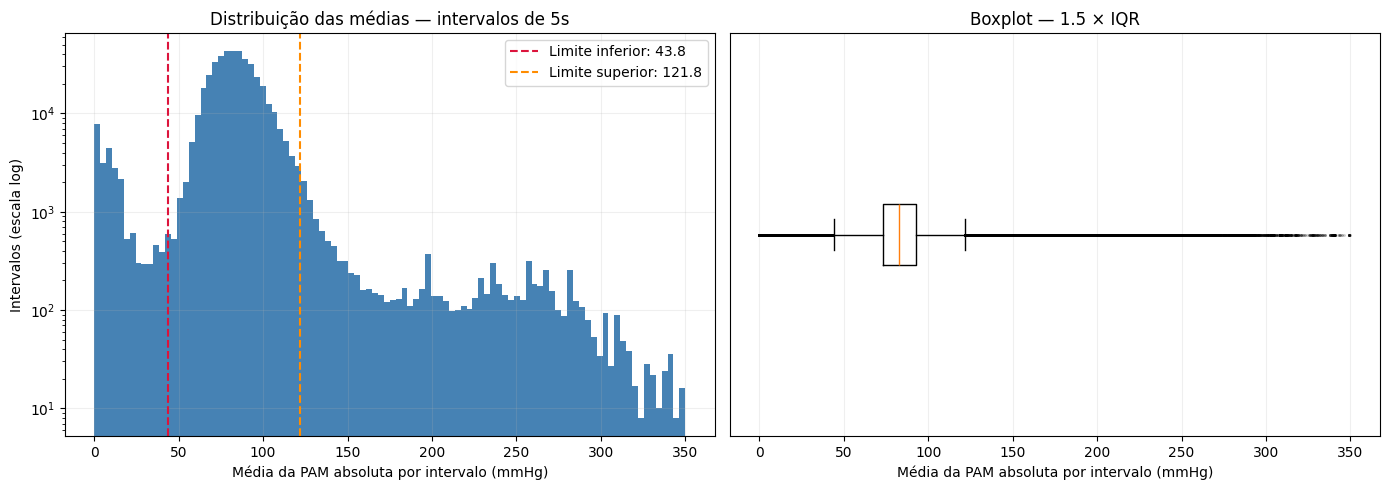

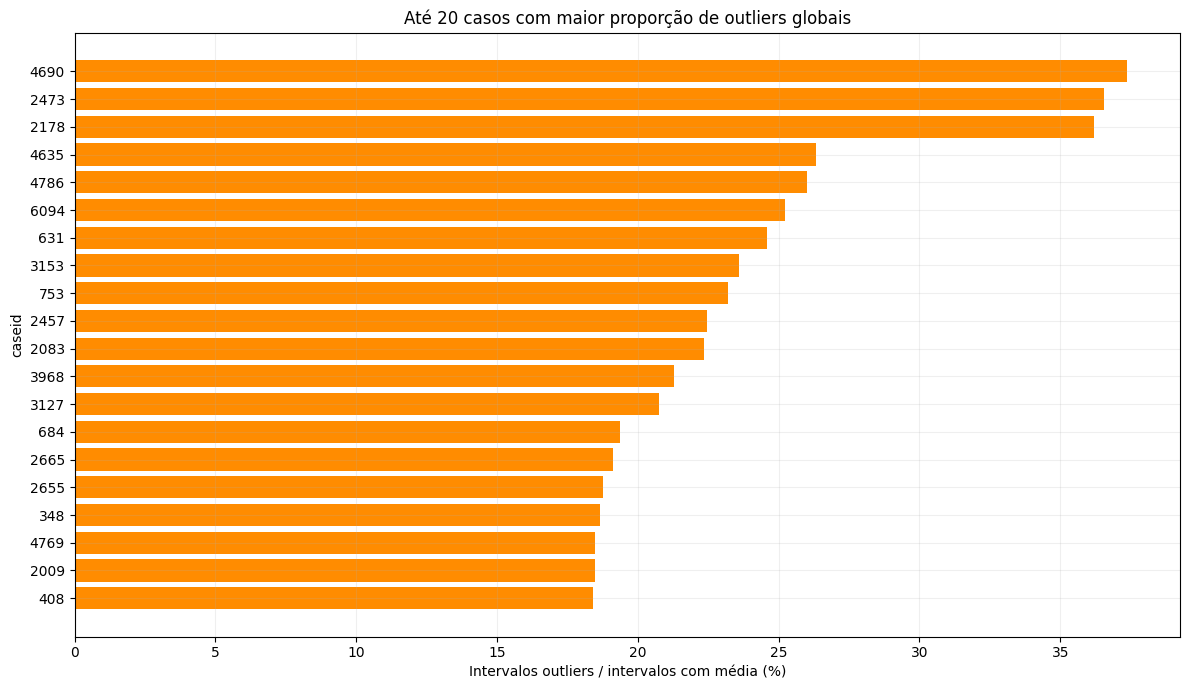

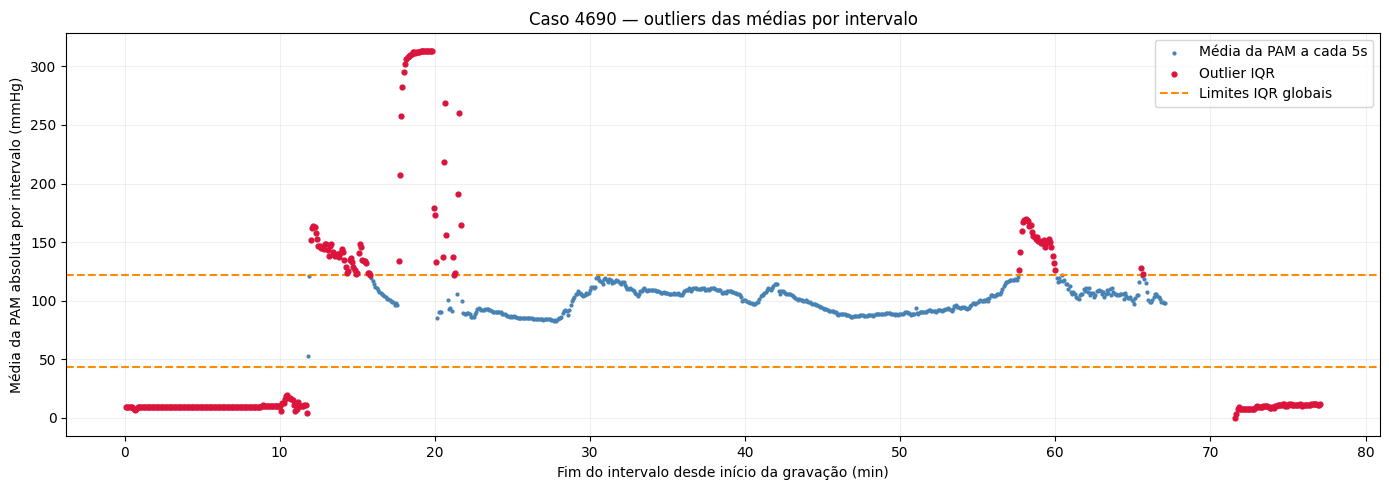

In [7]:
finitos = np.isfinite(dados[PAM])
valores = dados.loc[finitos, PAM]
if len(valores) < 4:
    raise ValueError('São necessárias pelo menos quatro médias finitas de PAM.')
q1, mediana, q3 = valores.quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
if iqr <= 0:
    raise ValueError('IQR zero: revise a distribuição antes de definir outliers.')
inferior, superior = q1 - FATOR_IQR * iqr, q3 + FATOR_IQR * iqr
dados['outlier_iqr'] = pd.Series(pd.NA, index=dados.index, dtype='boolean')
dados.loc[finitos, 'outlier_iqr'] = (valores.lt(inferior) | valores.gt(superior)).to_numpy()
mascara = dados['outlier_iqr'].fillna(False).astype(bool)
resumo = dados.groupby('caseid').agg(
    intervalos=('tempo_s', 'size'), intervalos_com_media=('outlier_iqr', 'count'),
    outliers=('outlier_iqr', 'sum'))
resumo['outliers_percentual'] = 100 * resumo['outliers'] / resumo['intervalos_com_media'].replace(0, np.nan)
resumo = resumo.sort_values(['outliers_percentual', 'caseid'], ascending=[False, True])
resumo.to_csv(SAIDA / 'resumo_outliers_por_caso.csv')
dados.to_parquet(SAIDA / 'pam_classificada_iqr.parquet', index=False)
dados.loc[mascara].to_parquet(SAIDA / 'outliers_pam_iqr.parquet', index=False)
print(f'Q1={q1:.2f}; mediana={mediana:.2f}; Q3={q3:.2f}; IQR={iqr:.2f} mmHg')
print(f'Limites estatísticos: {inferior:.2f} e {superior:.2f} mmHg')
print(f'{mascara.sum():,} outliers em {len(valores):,} intervalos com média ({100*mascara.sum()/len(valores):.2f}%).')
print(f'{(~finitos).sum():,} intervalos sem classificação por falta de média finita.')
display(resumo.head(20))

def salvar_figura(fig, nome):
    fig.tight_layout()
    fig.savefig(FIGURAS / nome, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(valores, bins=100, color='steelblue', log=True)
axes[0].axvline(inferior, color='crimson', linestyle='--', label=f'Limite inferior: {inferior:.1f}')
axes[0].axvline(superior, color='darkorange', linestyle='--', label=f'Limite superior: {superior:.1f}')
axes[0].set(xlabel='Média da PAM absoluta por intervalo (mmHg)', ylabel='Intervalos (escala log)', title=f'Distribuição das médias — intervalos de {INTERVALO_SEGUNDOS}s')
axes[0].legend()
axes[1].boxplot(valores.to_numpy(), vert=False, whis=FATOR_IQR,
                flierprops={'marker': '.', 'markersize': 2, 'alpha': 0.2})
axes[1].set(xlabel='Média da PAM absoluta por intervalo (mmHg)', title=f'Boxplot — {FATOR_IQR} × IQR', yticks=[])
salvar_figura(fig, 'distribuicao_boxplot_pam.png')

ranking = resumo.dropna(subset=['outliers_percentual']).head(20).sort_values('outliers_percentual')
fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(ranking.index.astype(str), ranking['outliers_percentual'], color='darkorange')
ax.set(xlabel='Intervalos outliers / intervalos com média (%)', ylabel='caseid', title='Até 20 casos com maior proporção de outliers globais')
salvar_figura(fig, 'outliers_por_caso.png')

caso = int(resumo.dropna(subset=['outliers_percentual']).index[0]) if CASO_GRAFICO is None else int(CASO_GRAFICO)
serie = dados.loc[dados.caseid.eq(caso)].sort_values('tempo_s').copy()
if serie.empty:
    raise ValueError(f'Caso {caso} não está na base.')
serie.loc[~np.isfinite(serie[PAM]), PAM] = np.nan
pontos = serie.loc[serie['outlier_iqr'].fillna(False)]
fig, ax = plt.subplots(figsize=(14, 5))
# Pontos não conectam medições através das lacunas temporais.
ax.scatter(serie.tempo_s / 60, serie[PAM], s=4, color='steelblue', label=f'Média da PAM a cada {INTERVALO_SEGUNDOS}s')
ax.scatter(pontos.tempo_s / 60, pontos[PAM], s=12, color='crimson', label='Outlier IQR', zorder=3)
ax.axhline(inferior, color='darkorange', linestyle='--', label='Limites IQR globais')
ax.axhline(superior, color='darkorange', linestyle='--')
ax.set(xlabel='Fim do intervalo desde início da gravação (min)', ylabel='Média da PAM absoluta por intervalo (mmHg)',
       title=f'Caso {caso} — outliers das médias por intervalo')
ax.legend()
salvar_figura(fig, f'serie_pam_caso_{caso:04d}.png')

## Rastreabilidade e limites da análise

As saídas da execução incluem `pam_tratada.parquet` e `registros_excluidos_artefatos.parquet`, além de: dois dicionários Markdown, inventário, base unificada, PAM classificada, somente outliers, resumo por caso, figuras PNG e manifesto JSON.

A classificação preserva a chave temporal. Linhas sem valor finito não são classificadas como normais. A análise não distingue artefato de alteração fisiológica e não estima sensibilidade ou precisão clínica, pois não há rótulos de referência. Para avançar à detecção de novas entradas, separar pacientes antes de ajustar limites/modelos e avaliar persistência temporal dos desvios.

Nesta versão, `pam_por_intervalo.parquet`, os arquivos de classificação e os gráficos contêm uma linha/ponto por intervalo. `sinais_unificados.parquet` continua preservando todos os registros. As saídas ficam em `vitaldb/vitaldb_200/analise_por_intervalo/<INTERVALO_SEGUNDOS>s/`. O tempo de fechamento do bloco está em `tempo_s`; início/fim e contagens estão nas colunas da base agregada.

A anotação de qualidade gera também `episodios_qualidade_pam.csv/.parquet`, `resumo_qualidade_pam.csv` e gráficos de exemplos. As suspeitas não são rótulos clínicos; sem exclusão automática por padrão.

In [8]:
manifesto = {
    'gerado_em_utc': agora, 'python': platform.python_version(),
    'versoes': {p: importlib.metadata.version(p) for p in ['pandas', 'numpy', 'pyarrow', 'matplotlib']},
    'entrada': str(BASE / 'sinais'), 'arquivos': len(ARQUIVOS), 'linhas': TOTAL,
    'casos': len(casos_vistos), 'pacientes': int(clinicos.subjectid.nunique()),
    'coluna_analisada': PAM,
    'filtro_artefatos': {'parametros': asdict(PARAMETROS_QUALIDADE),
        'regra': 'episódios por caso; PAM original; contexto insuficiente preservado',
        'contagens': resumo_filtro},
    'intervalo_segundos': int(INTERVALO_SEGUNDOS), 'intervalos': len(dados),
    'agregacao': 'média aritmética de abs(PAM) finita; por caso; blocos [inicio, fim)',
    'tempo_s_agregado': 'fim do intervalo; revisão do filtro requer contexto futuro adicional',
    'transformacao_pam': 'valor absoluto; não implica validação clínica',
    'coluna_original': PAM_ORIGINAL, 'indicador_negativo_original': FLAG_NEGATIVA,
    'negativos_finitos_convertidos': int(registros[FLAG_NEGATIVA].sum()), 'metodo': 'IQR global retrospectivo das médias finitas por intervalo',
    'fator_iqr': FATOR_IQR, 'q1': float(q1), 'mediana': float(mediana), 'q3': float(q3),
    'limite_inferior': float(inferior), 'limite_superior': float(superior),
    'intervalos_com_media_finita': len(valores), 'outliers': int(mascara.sum()),
    'sem_classificacao': int((~finitos).sum()), 'caso_grafico': caso,
    'entradas': [{'arquivo': p.name, 'bytes': p.stat().st_size, 'mtime_ns': p.stat().st_mtime_ns}
                 for p in ARQUIVOS],
}
(SAIDA / 'manifesto.json').write_text(json.dumps(manifesto, ensure_ascii=False, indent=2), encoding='utf-8')
print('Execução concluída. Arquivos gerados:')
for caminho in sorted(SAIDA.rglob('*')):
    if caminho.is_file():
        print(caminho.relative_to(SAIDA))

Execução concluída. Arquivos gerados:
DICIONARIO_DADOS.md
DICIONARIO_SINAIS_PARQUET.md
episodios_qualidade_pam.csv
episodios_qualidade_pam.parquet
figuras/distribuicao_boxplot_pam.png
figuras/outliers_por_caso.png
figuras/qualidade_exemplo_extremo_preservado.png
figuras/qualidade_exemplo_inconclusivo.png
figuras/qualidade_exemplo_possivel_flush.png
figuras/qualidade_exemplo_suspeita_sinal_baixo_constante.png
figuras/serie_pam_caso_0631.png
figuras/serie_pam_caso_4690.png
inventario.csv
manifesto.json
outliers_pam_iqr.parquet
pam_classificada_iqr.parquet
pam_por_intervalo.parquet
pam_tratada.parquet
registros_excluidos_artefatos.parquet
resumo_outliers_por_caso.csv
resumo_qualidade_pam.csv
sinais_unificados.parquet
